# Valid Pixel Mask Analysis: CLAHE Order and Threshold

Notebook ini memverifikasi secara empiris dua pertanyaan tentang `valid_pixel_mask` di `src/common/preprocess.py`:

- Apakah urutan saat ini (CLAHE dulu, baru filtering) menyebabkan pixel near-glare "bocor" masuk valid mask?
- Apakah threshold `high=240` terlalu tinggi untuk jaringan yang mengandung hemoglobin?

Analisis dijalankan terhadap ketiga situs (conjunctiva, palm, nail) karena fungsi `valid_pixel_mask` yang sama dipakai di seluruh pipeline.

## Environment Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from configs import paths
from src.common import qc, preprocess, features
from src.sites.conjunctiva import data as conj_data

SITES = ["conjunctiva", "palm", "nail"]

manifests = {}
for site in SITES:
    if site == "conjunctiva":
        df = conj_data.build_manifest(save=False)
    else:
        csv_path = paths.outputs_dir(site) / "manifest.csv"
        df = pd.read_csv(csv_path)
    df = df[df["roi_path"].astype(str).str.len() > 0].reset_index(drop=True)
    manifests[site] = df
    print(f"{site}: {len(df)} sampel dengan ROI")

Eyes-Defy Italy melewati 2 folder tanpa metadata atau file lengkap: [93, 95]
Eyes-Defy India melewati 1 folder tanpa metadata atau file lengkap: [7]
conjunctiva: 925 sampel dengan ROI
palm: 809 sampel dengan ROI
nail: 803 sampel dengan ROI


## Analysis 1: Raw Channel Max Distribution

Distribusi nilai `channel_max = rgb.max(axis=2)` pada pixel ROI sebelum CLAHE, per situs. Tujuan: memverifikasi apakah benar rata-rata channel_max di dataset tidak melebihi 200, dan berapa fraksi pixel yang berada di rentang 200-240 (near-glare) serta di atas 240.

In [2]:
raw_stats = {}

for site in SITES:
    df = manifests[site]
    all_channel_max = []
    per_image_medians = []
    per_image_p95 = []

    for _, row in df.iterrows():
        rgb, mask = qc.load_roi(row["roi_path"])
        rgb_cropped, mask_cropped = preprocess.crop_to_roi(rgb, mask)
        channel_max = rgb_cropped.max(axis=2)[mask_cropped]
        all_channel_max.append(channel_max)
        per_image_medians.append(float(np.median(channel_max)))
        per_image_p95.append(float(np.percentile(channel_max, 95)))

    pooled = np.concatenate(all_channel_max)

    frac_200_210 = float(((pooled >= 200) & (pooled < 210)).mean())
    frac_210_220 = float(((pooled >= 210) & (pooled < 220)).mean())
    frac_220_230 = float(((pooled >= 220) & (pooled < 230)).mean())
    frac_230_240 = float(((pooled >= 230) & (pooled < 240)).mean())
    frac_ge240 = float((pooled >= 240).mean())

    stats = {
        "n_images": len(df),
        "n_pixels": len(pooled),
        "mean": float(pooled.mean()),
        "median": float(np.median(pooled)),
        "p90": float(np.percentile(pooled, 90)),
        "p95": float(np.percentile(pooled, 95)),
        "p99": float(np.percentile(pooled, 99)),
        "frac_200_210": frac_200_210,
        "frac_210_220": frac_210_220,
        "frac_220_230": frac_220_230,
        "frac_230_240": frac_230_240,
        "frac_ge240": frac_ge240,
        "per_image_median_mean": float(np.mean(per_image_medians)),
        "per_image_p95_mean": float(np.mean(per_image_p95)),
        "pooled": pooled,
    }

    raw_stats[site] = stats
    print(f"\n--- {site} ({stats['n_images']} citra, {stats['n_pixels']:,} pixel ROI) ---")
    print(f"  mean channel_max:   {stats['mean']:.1f}")
    print(f"  median channel_max: {stats['median']:.1f}")
    print(f"  P90:  {stats['p90']:.1f}")
    print(f"  P95:  {stats['p95']:.1f}")
    print(f"  P99:  {stats['p99']:.1f}")
    print(f"  per-image median (mean): {stats['per_image_median_mean']:.1f}")
    print(f"  per-image P95 (mean):    {stats['per_image_p95_mean']:.1f}")
    print(f"  frac [200,210): {frac_200_210:.4f}")
    print(f"  frac [210,220): {frac_210_220:.4f}")
    print(f"  frac [220,230): {frac_220_230:.4f}")
    print(f"  frac [230,240): {frac_230_240:.4f}")
    print(f"  frac >= 240:    {frac_ge240:.4f}")


--- conjunctiva (925 citra, 15,405,233 pixel ROI) ---
  mean channel_max:   179.5
  median channel_max: 181.0
  P90:  219.0
  P95:  231.0
  P99:  249.0
  per-image median (mean): 190.1
  per-image P95 (mean):    206.5
  frac [200,210): 0.0822
  frac [210,220): 0.0645
  frac [220,230): 0.0411
  frac [230,240): 0.0239
  frac >= 240:    0.0293



--- palm (809 citra, 1,007,423,745 pixel ROI) ---
  mean channel_max:   224.7
  median channel_max: 243.0
  P90:  255.0
  P95:  255.0
  P99:  255.0
  per-image median (mean): 243.6
  per-image P95 (mean):    254.9
  frac [200,210): 0.0314
  frac [210,220): 0.0476
  frac [220,230): 0.0774
  frac [230,240): 0.1363
  frac >= 240:    0.5796



--- nail (803 citra, 87,819,744 pixel ROI) ---
  mean channel_max:   180.9
  median channel_max: 186.0
  P90:  212.0
  P95:  219.0
  P99:  231.0
  per-image median (mean): 185.5
  per-image P95 (mean):    216.9
  frac [200,210): 0.1366
  frac [210,220): 0.0790
  frac [220,230): 0.0343
  frac [230,240): 0.0089
  frac >= 240:    0.0039


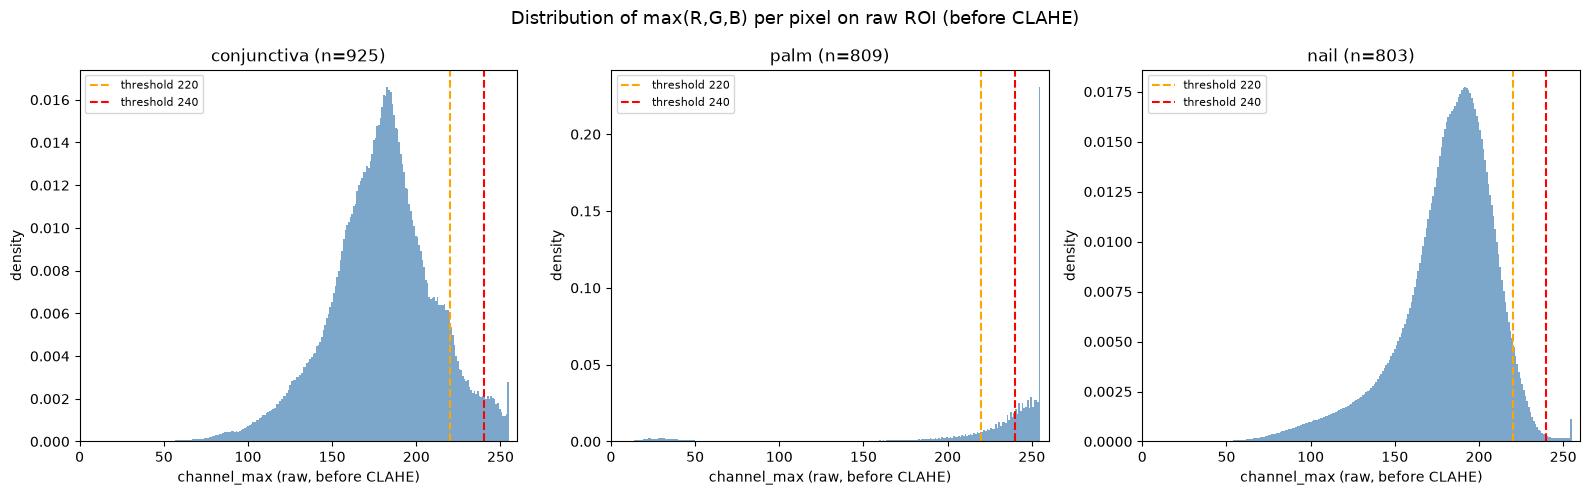

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, site in zip(axes, SITES):
    pooled = raw_stats[site]["pooled"]
    ax.hist(pooled, bins=256, range=(0, 255), color="steelblue", alpha=0.7, density=True)
    for threshold, color, label in [(220, "orange", "220"), (240, "red", "240")]:
        ax.axvline(threshold, color=color, linestyle="--", linewidth=1.5, label=f"threshold {label}")
    ax.set_title(f"{site} (n={raw_stats[site]['n_images']})")
    ax.set_xlabel("channel_max (raw, before CLAHE)")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
    ax.set_xlim(0, 260)
fig.suptitle("Distribution of max(R,G,B) per pixel on raw ROI (before CLAHE)", fontsize=13)
plt.tight_layout()
plt.show()

## Analysis 2: CLAHE Pixel Leakage

Membandingkan pixel-per-pixel sebelum dan sesudah CLAHE untuk mengukur dua fenomena:

- **Leaked pixels**: awalnya channel_max >= T (near-glare), setelah CLAHE turun ke bawah 240, sehingga lolos valid_pixel_mask padahal seharusnya terbuang.
- **Pushed pixels**: awalnya channel_max < T (baik), setelah CLAHE naik ke atas 240, sehingga terbuang padahal seharusnya valid.

Analisis dilakukan pada dua threshold T: 220 dan 230.

In [4]:
leakage_results = {}

for site in SITES:
    df = manifests[site]
    records = []

    for _, row in df.iterrows():
        rgb, mask = qc.load_roi(row["roi_path"])
        rgb_cropped, mask_cropped = preprocess.crop_to_roi(rgb, mask)

        raw_cmax = rgb_cropped.max(axis=2)
        clahe_rgb = preprocess.clahe_on_v(rgb_cropped)
        clahe_cmax = clahe_rgb.max(axis=2)

        roi_pixels = mask_cropped.sum()
        if roi_pixels < 10:
            continue

        rec = {"uid": row["uid"], "roi_pixels": int(roi_pixels)}

        for T in [220, 230]:
            leaked = mask_cropped & (raw_cmax >= T) & (clahe_cmax < 240)
            pushed = mask_cropped & (raw_cmax < T) & (clahe_cmax >= 240)
            rec[f"leaked_{T}"] = int(leaked.sum())
            rec[f"pushed_{T}"] = int(pushed.sum())
            rec[f"leaked_{T}_frac"] = float(leaked.sum()) / roi_pixels
            rec[f"pushed_{T}_frac"] = float(pushed.sum()) / roi_pixels

        records.append(rec)

    result_df = pd.DataFrame(records)
    leakage_results[site] = result_df

    print(f"\n--- {site} ({len(result_df)} citra) ---")
    for T in [220, 230]:
        leaked_col = f"leaked_{T}_frac"
        pushed_col = f"pushed_{T}_frac"
        print(f"  Threshold T={T}:")
        print(f"    leaked (raw>={T}, clahe<240): mean={result_df[leaked_col].mean():.6f}, "
              f"median={result_df[leaked_col].median():.6f}, max={result_df[leaked_col].max():.6f}")
        print(f"    pushed (raw<{T}, clahe>=240): mean={result_df[pushed_col].mean():.6f}, "
              f"median={result_df[pushed_col].median():.6f}, max={result_df[pushed_col].max():.6f}")
        images_with_leak = (result_df[leaked_col] > 0).sum()
        images_with_push = (result_df[pushed_col] > 0).sum()
        print(f"    citra dengan leaked > 0: {images_with_leak}/{len(result_df)} "
              f"({100*images_with_leak/max(len(result_df),1):.1f}%)")
        print(f"    citra dengan pushed > 0: {images_with_push}/{len(result_df)} "
              f"({100*images_with_push/max(len(result_df),1):.1f}%)")


--- conjunctiva (925 citra) ---
  Threshold T=220:
    leaked (raw>=220, clahe<240): mean=0.117555, median=0.000477, max=0.809988
    pushed (raw<220, clahe>=240): mean=0.048329, median=0.000000, max=0.918067
    citra dengan leaked > 0: 541/925 (58.5%)
    citra dengan pushed > 0: 222/925 (24.0%)
  Threshold T=230:
    leaked (raw>=230, clahe<240): mean=0.060855, median=0.000000, max=0.668497
    pushed (raw<230, clahe>=240): mean=0.072479, median=0.000000, max=0.984212
    citra dengan leaked > 0: 417/925 (45.1%)
    citra dengan pushed > 0: 295/925 (31.9%)



--- palm (809 citra) ---
  Threshold T=220:
    leaked (raw>=220, clahe<240): mean=0.427720, median=0.442861, max=0.687794
    pushed (raw<220, clahe>=240): mean=0.000005, median=0.000000, max=0.000385
    citra dengan leaked > 0: 809/809 (100.0%)
    citra dengan pushed > 0: 61/809 (7.5%)
  Threshold T=230:
    leaked (raw>=230, clahe<240): mean=0.348374, median=0.359986, max=0.605658
    pushed (raw<230, clahe>=240): mean=0.000139, median=0.000000, max=0.003199
    citra dengan leaked > 0: 809/809 (100.0%)
    citra dengan pushed > 0: 369/809 (45.6%)



--- nail (803 citra) ---
  Threshold T=220:
    leaked (raw>=220, clahe<240): mean=0.044673, median=0.036501, max=0.552342
    pushed (raw<220, clahe>=240): mean=0.000051, median=0.000000, max=0.000923
    citra dengan leaked > 0: 798/803 (99.4%)
    citra dengan pushed > 0: 317/803 (39.5%)
  Threshold T=230:
    leaked (raw>=230, clahe<240): mean=0.009845, median=0.003604, max=0.446779
    pushed (raw<230, clahe>=240): mean=0.000105, median=0.000019, max=0.001879
    citra dengan leaked > 0: 744/803 (92.7%)
    citra dengan pushed > 0: 488/803 (60.8%)


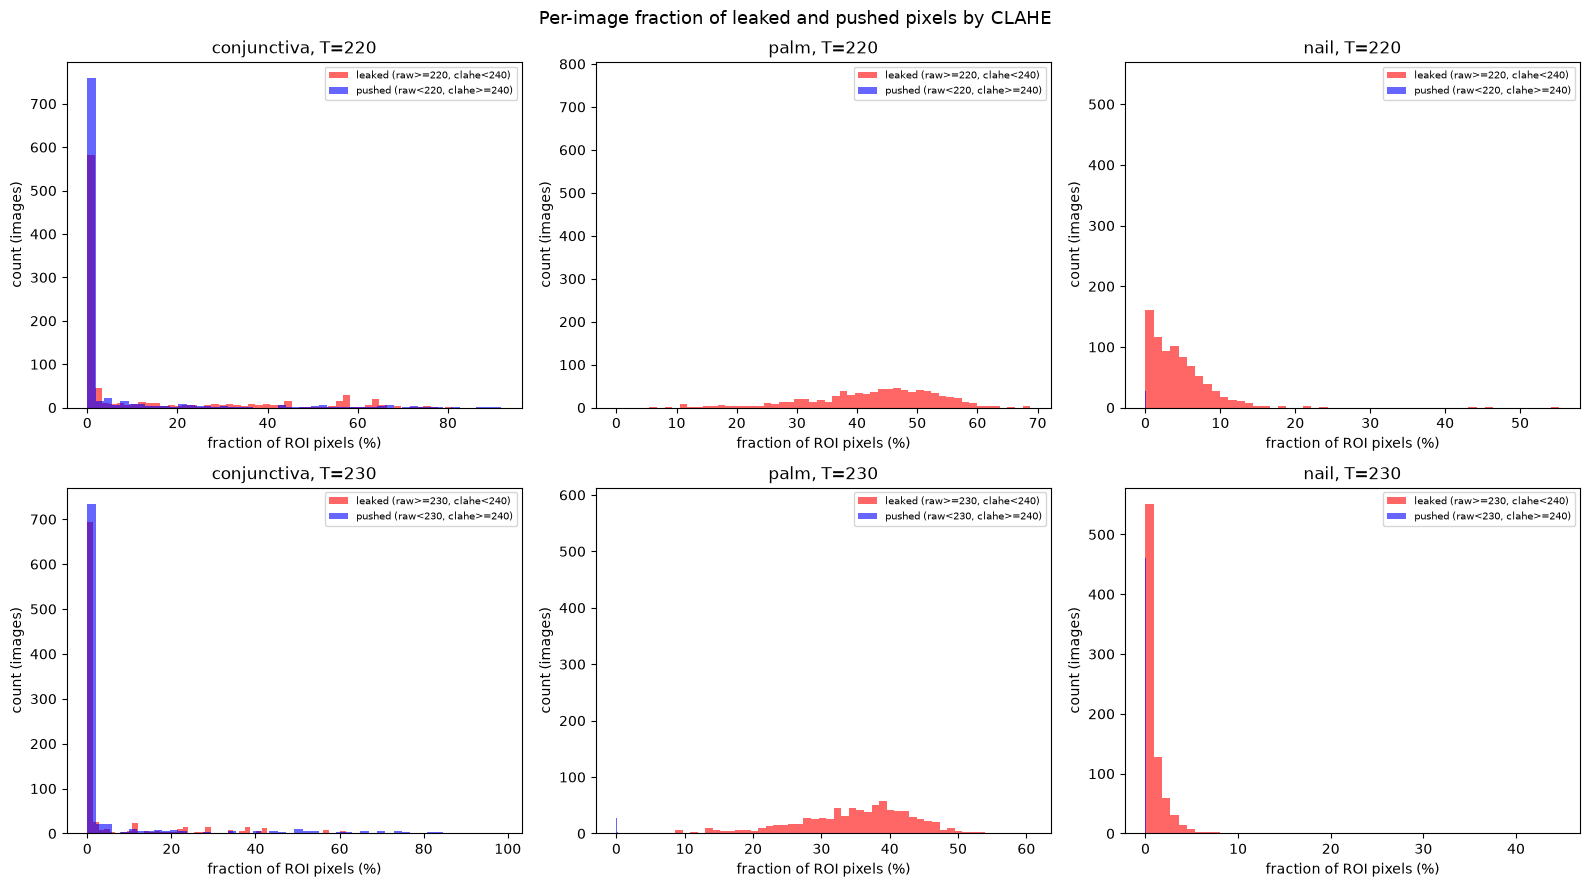

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col_idx, site in enumerate(SITES):
    result_df = leakage_results[site]
    for row_idx, T in enumerate([220, 230]):
        ax = axes[row_idx, col_idx]
        leaked_frac = result_df[f"leaked_{T}_frac"] * 100
        pushed_frac = result_df[f"pushed_{T}_frac"] * 100
        ax.hist(leaked_frac, bins=50, alpha=0.6, color="red", label=f"leaked (raw>={T}, clahe<240)")
        ax.hist(pushed_frac, bins=50, alpha=0.6, color="blue", label=f"pushed (raw<{T}, clahe>=240)")
        ax.set_title(f"{site}, T={T}")
        ax.set_xlabel("fraction of ROI pixels (%)")
        ax.set_ylabel("count (images)")
        ax.legend(fontsize=7)

fig.suptitle("Per-image fraction of leaked and pushed pixels by CLAHE", fontsize=13)
plt.tight_layout()
plt.show()

## Analysis 2b: Visual Examples of Leaked Pixels

Overlay visual pada 2 sampel per situs yang memiliki leaked pixel terbanyak pada T=220. Pixel leaked ditandai merah, pixel pushed ditandai biru.

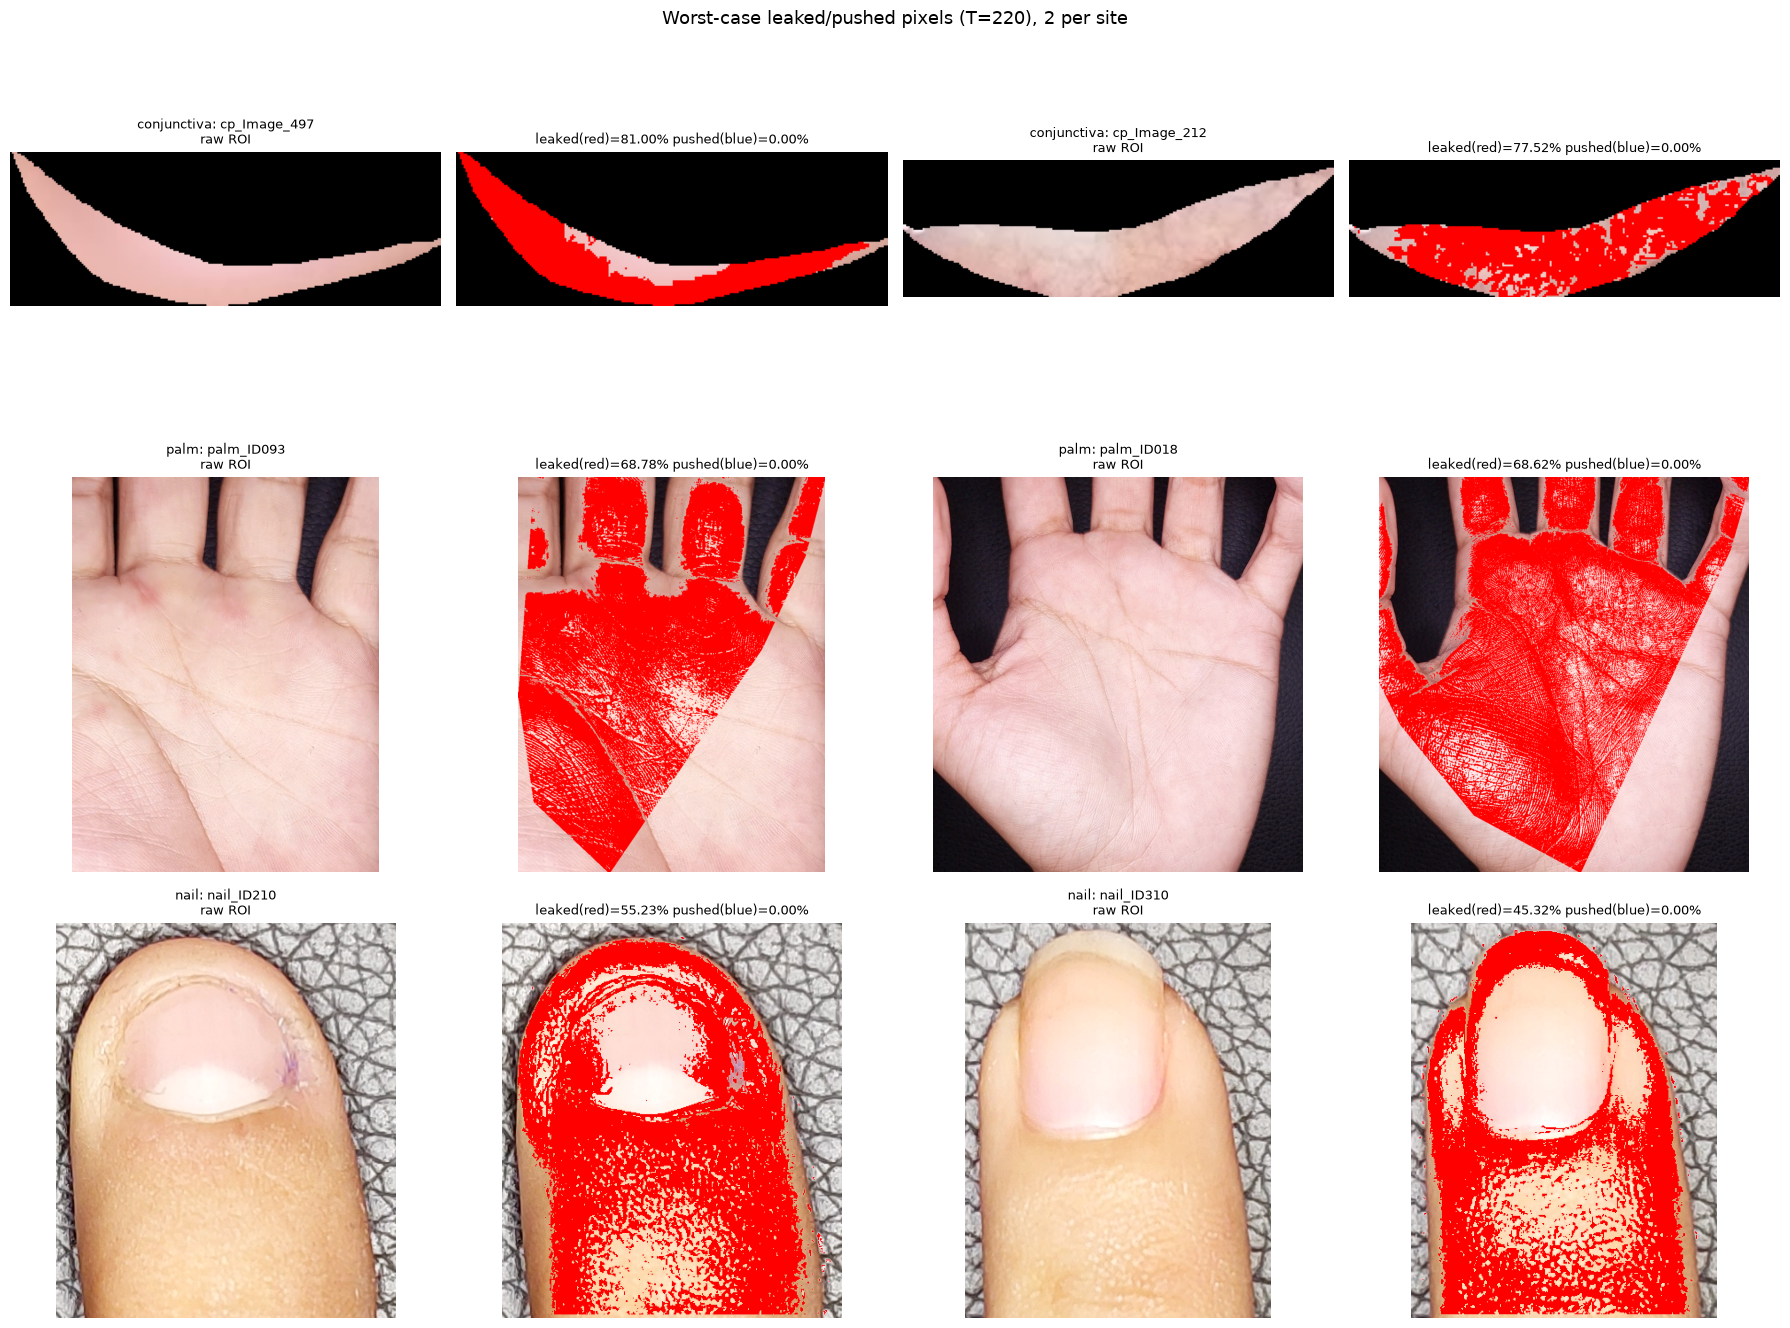

In [6]:
T_VIS = 220

fig, axes = plt.subplots(len(SITES), 4, figsize=(18, 4.5 * len(SITES)))

for row_idx, site in enumerate(SITES):
    result_df = leakage_results[site]
    top2 = result_df.nlargest(2, f"leaked_{T_VIS}_frac")
    df = manifests[site]

    for pair_idx, (_, sample_row) in enumerate(top2.iterrows()):
        uid = sample_row["uid"]
        roi_path = df.loc[df["uid"] == uid, "roi_path"].iloc[0]
        rgb, mask = qc.load_roi(roi_path)
        rgb_cropped, mask_cropped = preprocess.crop_to_roi(rgb, mask)

        raw_cmax = rgb_cropped.max(axis=2)
        clahe_rgb = preprocess.clahe_on_v(rgb_cropped)
        clahe_cmax = clahe_rgb.max(axis=2)

        leaked = mask_cropped & (raw_cmax >= T_VIS) & (clahe_cmax < 240)
        pushed = mask_cropped & (raw_cmax < T_VIS) & (clahe_cmax >= 240)

        overlay = rgb_cropped.copy()
        overlay[leaked] = [255, 0, 0]
        overlay[pushed] = [0, 0, 255]

        col_base = pair_idx * 2
        axes[row_idx, col_base].imshow(rgb_cropped)
        axes[row_idx, col_base].set_title(f"{site}: {uid}\nraw ROI", fontsize=9)
        axes[row_idx, col_base].axis("off")

        axes[row_idx, col_base + 1].imshow(overlay)
        leak_pct = 100 * sample_row[f"leaked_{T_VIS}_frac"]
        push_pct = 100 * sample_row[f"pushed_{T_VIS}_frac"]
        axes[row_idx, col_base + 1].set_title(
            f"leaked(red)={leak_pct:.2f}% pushed(blue)={push_pct:.2f}%", fontsize=9
        )
        axes[row_idx, col_base + 1].axis("off")

fig.suptitle(f"Worst-case leaked/pushed pixels (T={T_VIS}), 2 per site", fontsize=13)
plt.tight_layout()
plt.show()

## Analysis 3: Feature Impact Across Configurations

Membandingkan 27 fitur hand-crafted pada 4 konfigurasi pipeline per situs (30 sampel acak per situs). Konfigurasi:

- (A) CLAHE dulu, threshold 240 (baseline, pipeline saat ini)
- (B) CLAHE dulu, threshold 220
- (C) Filter dulu threshold 240, baru CLAHE
- (D) Filter dulu threshold 220, baru CLAHE

Tujuan: mengukur seberapa besar perubahan urutan dan threshold menggeser fitur yang masuk ke model.

In [7]:
CONFIG_NAMES = ["A: CLAHE->filter(240)", "B: CLAHE->filter(220)",
                "C: filter(240)->CLAHE", "D: filter(220)->CLAHE"]

SAMPLE_N = 30
KEY_FEATURES = ["mean_r", "mean_g", "mean_b", "erythema_index", "hhr", "mean_a",
                "g1", "g2", "g3", "g4", "g5", "entropy", "brightness"]


def compute_features_config(rgb, mask, config):
    """Hitung fitur hand-crafted untuk satu konfigurasi pipeline."""
    rgb_work = rgb.copy()
    mask_work = mask.copy()

    if config == "A":
        normalized = preprocess.clahe_on_v(rgb_work).copy()
        normalized[~mask_work] = 0
        valid = preprocess.valid_pixel_mask(normalized, mask_work, high=240)
    elif config == "B":
        normalized = preprocess.clahe_on_v(rgb_work).copy()
        normalized[~mask_work] = 0
        valid = preprocess.valid_pixel_mask(normalized, mask_work, high=220)
    elif config == "C":
        pre_valid = preprocess.valid_pixel_mask(rgb_work, mask_work, high=240)
        rgb_work[~pre_valid] = 0
        normalized = preprocess.clahe_on_v(rgb_work).copy()
        normalized[~pre_valid] = 0
        valid = pre_valid
    elif config == "D":
        pre_valid = preprocess.valid_pixel_mask(rgb_work, mask_work, high=220)
        rgb_work[~pre_valid] = 0
        normalized = preprocess.clahe_on_v(rgb_work).copy()
        normalized[~pre_valid] = 0
        valid = pre_valid

    return features.compute_handcrafted_features(normalized, valid)


feature_results = {}

for site in SITES:
    df = manifests[site]
    sample_df = df.sample(min(SAMPLE_N, len(df)), random_state=42).reset_index(drop=True)

    config_features = {c: [] for c in ["A", "B", "C", "D"]}

    for _, row in sample_df.iterrows():
        rgb, mask = qc.load_roi(row["roi_path"])
        rgb, mask = preprocess.crop_to_roi(rgb, mask)
        for c in ["A", "B", "C", "D"]:
            feat = compute_features_config(rgb, mask, c)
            config_features[c].append(feat)

    config_dfs = {}
    for c in ["A", "B", "C", "D"]:
        config_dfs[c] = pd.DataFrame(config_features[c])

    feature_results[site] = config_dfs
    print(f"\n--- {site} ({len(sample_df)} sampel) ---")
    print(f"{'feature':<20} {'A(baseline)':>12} {'B(clahe220)':>12} {'C(filt240)':>12} {'D(filt220)':>12} {'delta_B%':>10} {'delta_C%':>10} {'delta_D%':>10}")
    for feat_name in KEY_FEATURES:
        means = {c: config_dfs[c][feat_name].mean() for c in ["A", "B", "C", "D"]}
        base = means["A"]
        if abs(base) < 1e-8:
            deltas = {c: 0.0 for c in ["B", "C", "D"]}
        else:
            deltas = {c: 100 * (means[c] - base) / abs(base) for c in ["B", "C", "D"]}
        print(f"{feat_name:<20} {base:12.4f} {means['B']:12.4f} {means['C']:12.4f} {means['D']:12.4f} {deltas['B']:9.2f}% {deltas['C']:9.2f}% {deltas['D']:9.2f}%")


--- conjunctiva (30 sampel) ---
feature               A(baseline)  B(clahe220)   C(filt240)   D(filt220)   delta_B%   delta_C%   delta_D%
mean_r                   194.2822     161.1566     198.4310     186.0224    -17.05%      2.14%     -4.25%
mean_g                   116.0010      90.3449     120.3000     108.0336    -22.12%      3.71%     -6.87%
mean_b                   110.4007      85.9893     114.7453     103.9085    -22.11%      3.94%     -5.88%
erythema_index             0.3707       0.3838       0.3596       0.3776      3.51%     -3.01%      1.86%
hhr                        1.8072       1.7118       1.7979       1.8142     -5.28%     -0.51%      0.38%
mean_a                   158.2668     143.1672     158.0661     154.1955     -9.54%     -0.13%     -2.57%
g1                        24.9998      24.6078      30.6301      37.6908     -1.57%     22.52%     50.76%
g2                         6.2197       7.8803       5.5784       5.8074     26.70%    -10.31%     -6.63%
g3           


--- palm (30 sampel) ---
feature               A(baseline)  B(clahe220)   C(filt240)   D(filt220)   delta_B%   delta_C%   delta_D%
mean_r                   199.0037     179.1237     194.6286     173.8501     -9.99%     -2.20%    -12.64%
mean_g                   153.9973     132.5652     144.0949     117.3887    -13.92%     -6.43%    -23.77%
mean_b                   146.5506     124.8782     135.6090     109.0301    -14.79%     -7.47%    -25.60%
erythema_index             0.2198       0.2855       0.2489       0.3389     29.86%     13.22%     54.17%
hhr                        1.2934       1.3522       1.3519       1.4811      4.55%      4.53%     14.52%
mean_a                   143.8912     144.9523     146.0763     149.1799      0.74%      1.52%      3.68%
g1                         7.2120       6.6496      37.7502      30.6750     -7.80%    423.44%    325.33%
g2                         9.1360       9.0915       6.1337       6.7364     -0.49%    -32.86%    -26.27%
g3                  


--- nail (30 sampel) ---
feature               A(baseline)  B(clahe220)   C(filt240)   D(filt220)   delta_B%   delta_C%   delta_D%
mean_r                   175.3241     174.1787     170.9152     171.0511     -0.65%     -2.51%     -2.44%
mean_g                   118.4580     117.0335     115.7806     115.0075     -1.20%     -2.26%     -2.91%
mean_b                   118.5003     116.9066     115.8739     114.8111     -1.34%     -2.22%     -3.11%
erythema_index             0.3337       0.3389       0.3436       0.3464      1.56%      2.98%      3.82%
hhr                        1.4826       1.4907       1.4788       1.4895      0.54%     -0.26%      0.47%
mean_a                   150.5210     150.6377     149.9302     150.2489      0.08%     -0.39%     -0.18%
g1                         8.9133       8.7868       8.9498      11.9489     -1.42%      0.41%     34.06%
g2                         8.2160       8.3037       8.1935       8.1576      1.07%     -0.27%     -0.71%
g3                  

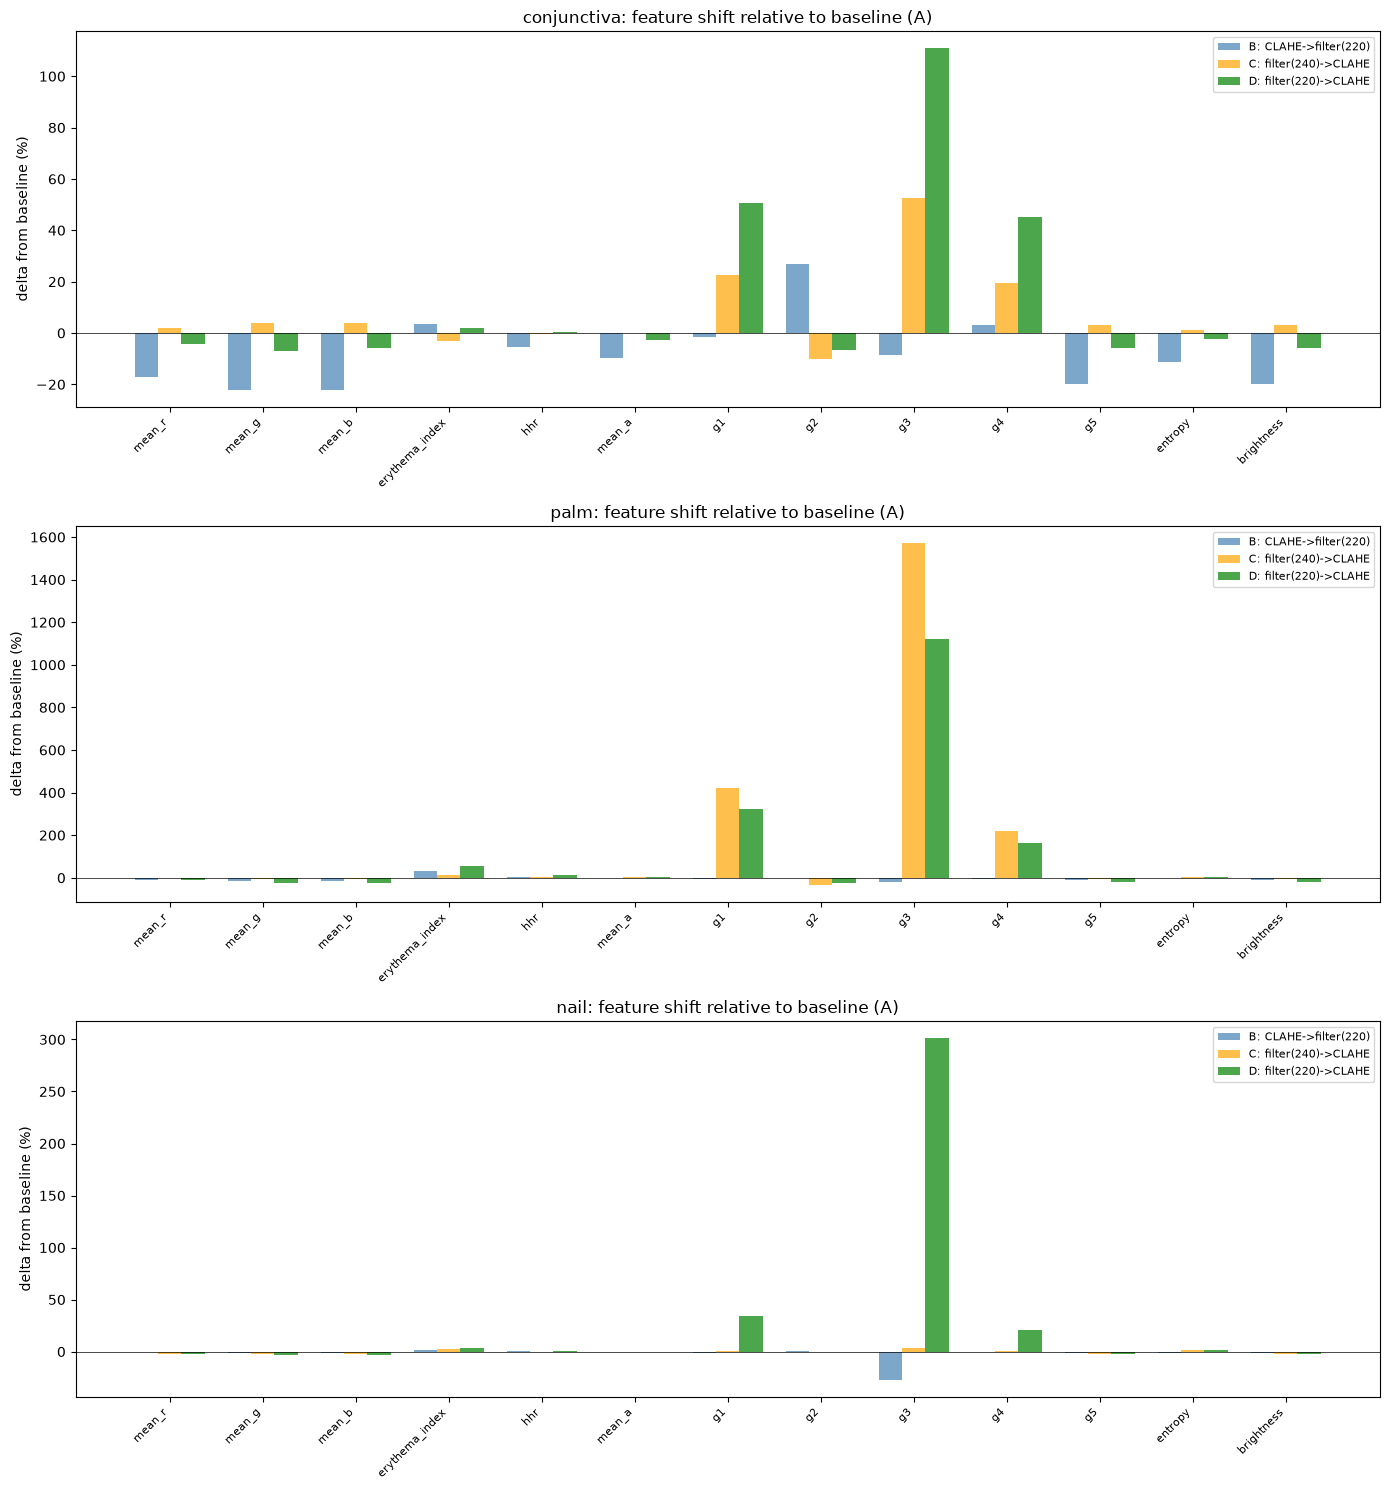

In [8]:
fig, axes = plt.subplots(len(SITES), 1, figsize=(14, 5 * len(SITES)))
if len(SITES) == 1:
    axes = [axes]

for ax, site in zip(axes, SITES):
    config_dfs = feature_results[site]
    base_means = config_dfs["A"][KEY_FEATURES].mean()

    x = np.arange(len(KEY_FEATURES))
    width = 0.25
    colors = ["steelblue", "orange", "green"]

    for i, (c, label, color) in enumerate(zip(["B", "C", "D"], CONFIG_NAMES[1:], colors)):
        other_means = config_dfs[c][KEY_FEATURES].mean()
        safe_base = base_means.replace(0, np.nan)
        deltas = 100 * (other_means - base_means) / safe_base.abs()
        deltas = deltas.fillna(0)
        ax.bar(x + (i - 1) * width, deltas.values, width, label=label, color=color, alpha=0.7)

    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_ylabel("delta from baseline (%)")
    ax.set_title(f"{site}: feature shift relative to baseline (A)")
    ax.set_xticks(x)
    ax.set_xticklabels(KEY_FEATURES, rotation=45, ha="right", fontsize=8)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Analysis 3b: Valid Pixel Count Change

Berapa persen pixel valid yang hilang atau bertambah dengan konfigurasi B, C, D relatif terhadap baseline A.

In [9]:
for site in SITES:
    df = manifests[site]
    sample_df = df.sample(min(SAMPLE_N, len(df)), random_state=42).reset_index(drop=True)

    pixel_counts = {c: [] for c in ["A", "B", "C", "D"]}

    for _, row in sample_df.iterrows():
        rgb, mask = qc.load_roi(row["roi_path"])
        rgb, mask = preprocess.crop_to_roi(rgb, mask)

        clahe = preprocess.clahe_on_v(rgb)
        clahe_zeroed = clahe.copy()
        clahe_zeroed[~mask] = 0

        valid_a = preprocess.valid_pixel_mask(clahe_zeroed, mask, high=240)
        valid_b = preprocess.valid_pixel_mask(clahe_zeroed, mask, high=220)

        pre_valid_c = preprocess.valid_pixel_mask(rgb, mask, high=240)
        pre_valid_d = preprocess.valid_pixel_mask(rgb, mask, high=220)

        pixel_counts["A"].append(int(valid_a.sum()))
        pixel_counts["B"].append(int(valid_b.sum()))
        pixel_counts["C"].append(int(pre_valid_c.sum()))
        pixel_counts["D"].append(int(pre_valid_d.sum()))

    print(f"\n--- {site} ({len(sample_df)} sampel) ---")
    print(f"{'config':<25} {'mean_valid':>12} {'mean_delta%':>12}")
    base = np.mean(pixel_counts["A"])
    for c, name in zip(["A", "B", "C", "D"], CONFIG_NAMES):
        m = np.mean(pixel_counts[c])
        delta = 100 * (m - base) / base if base > 0 else 0
        print(f"{name:<25} {m:12.0f} {delta:11.2f}%")


--- conjunctiva (30 sampel) ---
config                      mean_valid  mean_delta%
A: CLAHE->filter(240)            13988        0.00%
B: CLAHE->filter(220)            12786       -8.59%
C: filter(240)->CLAHE            14494        3.62%
D: filter(220)->CLAHE            12967       -7.30%



--- palm (30 sampel) ---
config                      mean_valid  mean_delta%
A: CLAHE->filter(240)           683209        0.00%
B: CLAHE->filter(220)           425512      -37.72%
C: filter(240)->CLAHE           430489      -36.99%
D: filter(220)->CLAHE           189949      -72.20%



--- nail (30 sampel) ---
config                      mean_valid  mean_delta%
A: CLAHE->filter(240)           109477        0.00%
B: CLAHE->filter(220)           106948       -2.31%
C: filter(240)->CLAHE           109626        0.14%
D: filter(220)->CLAHE           106290       -2.91%


## Summary

Tabel ringkasan dan rekomendasi akan ditulis setelah melihat output numerik di atas.

In [10]:
summary_rows = []
for site in SITES:
    rs = raw_stats[site]
    lr = leakage_results[site]
    summary_rows.append({
        "site": site,
        "n_images": rs["n_images"],
        "raw_cmax_mean": round(rs["mean"], 1),
        "raw_cmax_p95": round(rs["p95"], 1),
        "raw_cmax_p99": round(rs["p99"], 1),
        "frac_ge240": round(rs["frac_ge240"] * 100, 2),
        "frac_220_240": round((rs["frac_220_230"] + rs["frac_230_240"]) * 100, 2),
        "leaked_220_mean_pct": round(lr["leaked_220_frac"].mean() * 100, 4),
        "pushed_220_mean_pct": round(lr["pushed_220_frac"].mean() * 100, 4),
    })

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

       site  n_images  raw_cmax_mean  raw_cmax_p95  raw_cmax_p99  frac_ge240  frac_220_240  leaked_220_mean_pct  pushed_220_mean_pct
conjunctiva       925          179.5         231.0         249.0        2.93          6.49              11.7555               4.8329
       palm       809          224.7         255.0         255.0       57.96         21.38              42.7720               0.0005
       nail       803          180.9         219.0         231.0        0.39          4.32               4.4673               0.0051
